# Reusable EDA : Univariate, Bivariate & Multivariate
One class, three levels of analysis. Works on any DataFrame.

In [2]:
import numpy as np
import pandas as pd
from eda_multi_analysis_pipeline import EDAToolkit

## 1. Sample dataset (employee data, 300 rows, built with realistic relationships)

In [3]:
rng = np.random.default_rng(42)
n = 300
age = rng.integers(22, 60, n)
experience = np.clip(age - 22 - rng.integers(0, 5, n), 0, None)
department = rng.choice(['IT', 'HR', 'Sales', 'Finance'], n, p=[0.4, 0.15, 0.3, 0.15])
remote = rng.choice(['Yes', 'No'], n, p=[0.35, 0.65])
dept_bonus = pd.Series(department).map({'IT': 15000, 'HR': 0, 'Sales': 8000, 'Finance': 10000}).values
salary = 30000 + experience * 2500 + dept_bonus + rng.normal(0, 6000, n)
rating = np.clip(rng.normal(3.4, 0.7, n), 1, 5).round(1)
df = pd.DataFrame({'Age': age, 'Experience': experience, 'Rating': rating, 'Salary': salary.round(0),
                   'Department': department, 'Remote': remote})
df.loc[rng.choice(n, 12, replace=False), 'Rating'] = np.nan   # add missing values
df.head()

,Age,Experience,Rating,Salary,Department,Remote
0,25,2,3.1,39491.0,Sales,No
1,51,25,3.1,107220.0,IT,No
2,46,24,2.6,91673.0,HR,No
3,38,12,2.1,53953.0,HR,No
4,38,14,3.3,79346.0,Finance,No


## 2. Run everything


 0. DATA OVERVIEW
Shape: 300 rows x 6 columns
Numerical  (4): ['Age', 'Experience', 'Rating', 'Salary']
Categorical(2): ['Department', 'Remote']

Missing values:
         count  percent
Rating     12      4.0

Duplicate rows: 0

 1. UNIVARIATE ANALYSIS
Numeric summary:
             count      mean       std      min      25%      50%        75%  \
Age         300.0     40.45     10.34     22.0     32.0     40.0      49.00   
Experience  300.0     16.56     10.26      0.0      8.0     16.0      25.00   
Rating      288.0      3.40      0.74      1.3      2.9      3.4       3.90   
Salary      300.0  81201.66  26970.52  26571.0  58380.5  81455.0  105387.25   

                 max  skew  kurtosis  outliers  
Age             59.0 -0.04     -1.10         0  
Experience      36.0 -0.02     -1.13         0  
Rating           5.0 -0.16     -0.16         1  
Salary      131855.0 -0.09     -1.07         0  


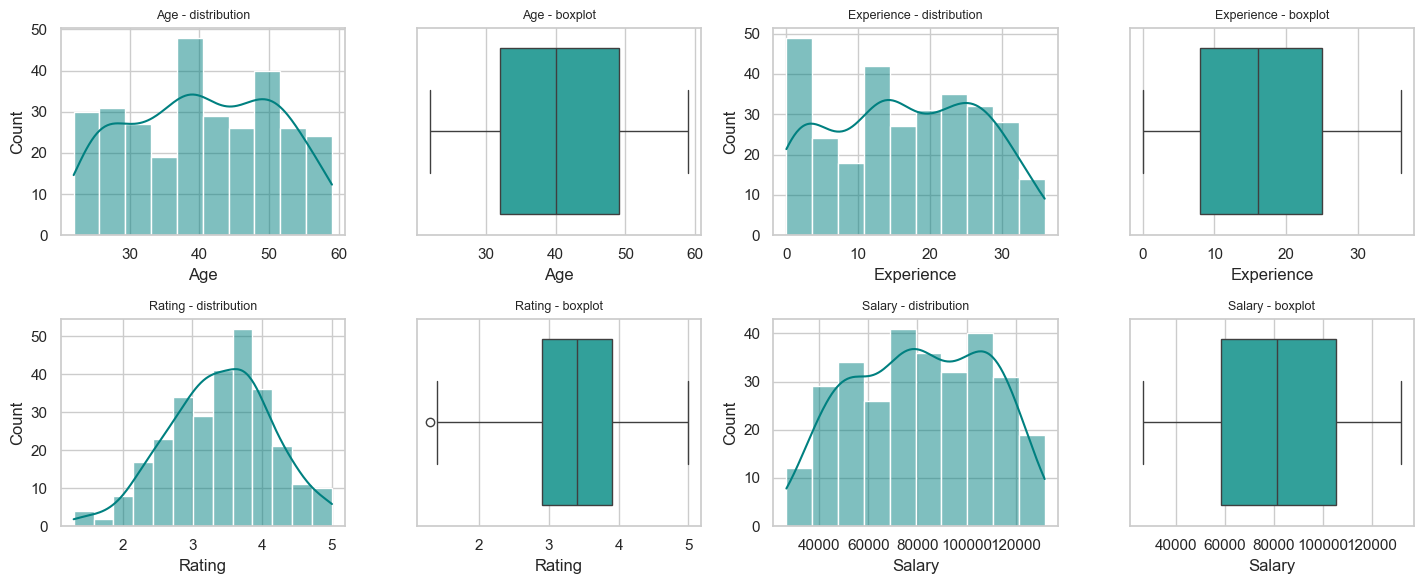


Department (% of rows):
Department
IT         38.3
Sales      33.0
HR         15.0
Finance    13.7

Remote (% of rows):
Remote
No     63.3
Yes    36.7


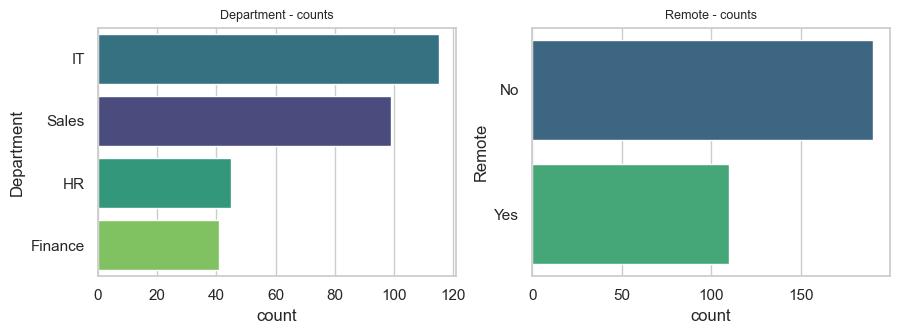


 2. BIVARIATE ANALYSIS
--- Numeric vs Numeric ---
     col_1      col_2  pearson  spearman
       Age Experience    0.990     0.989
Experience     Salary    0.957     0.958
       Age     Salary    0.948     0.949
Experience     Rating   -0.119    -0.105
    Rating     Salary   -0.118    -0.116
       Age     Rating   -0.113    -0.100
(Pearson = straight-line relationship, Spearman = any rising/falling relationship)


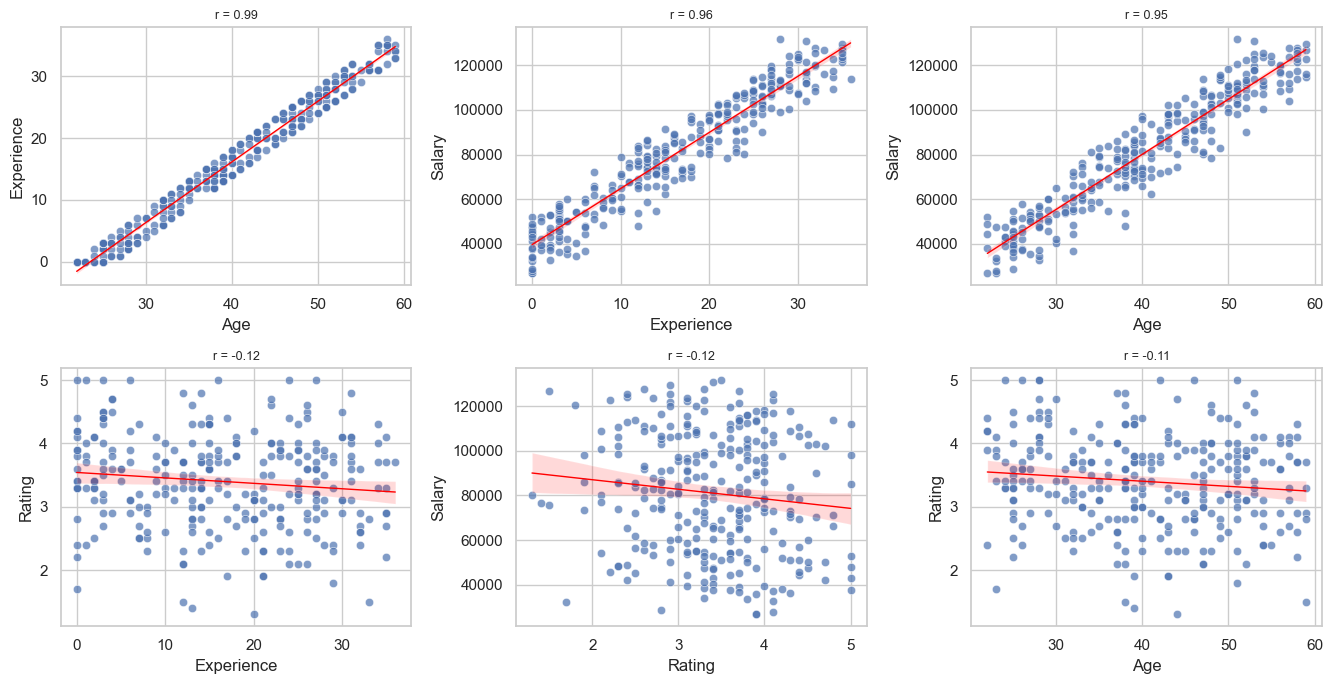


--- Category vs Numeric ---
  category numeric highest_group lowest_group  p_value
Department  Salary            IT           HR   0.0001
    Remote  Salary           Yes           No   0.5288
(p_value < 0.05 means the group averages are really different, not just chance)


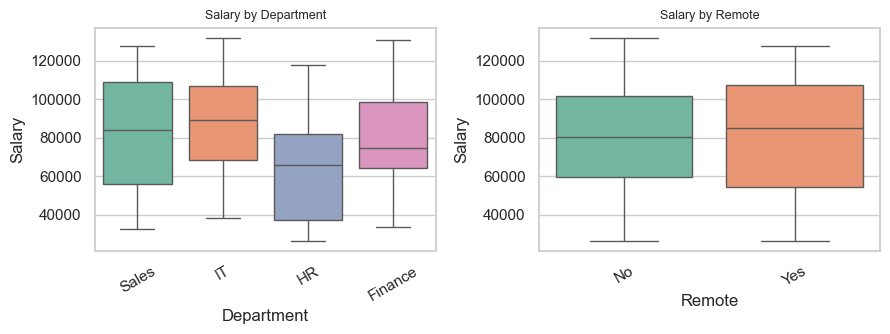


--- Category vs Category ---


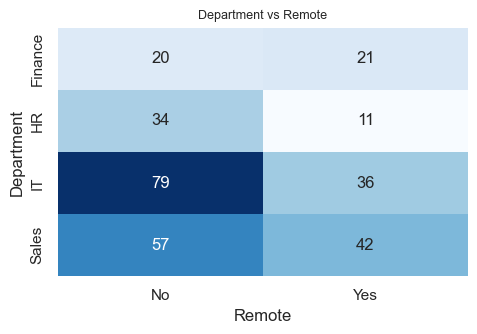

     col_1  col_2  p_value  cramers_v
Department Remote   0.0236     0.1777
(Cramer's V: 0 = no link, 1 = perfect link)

 3. MULTIVARIATE ANALYSIS


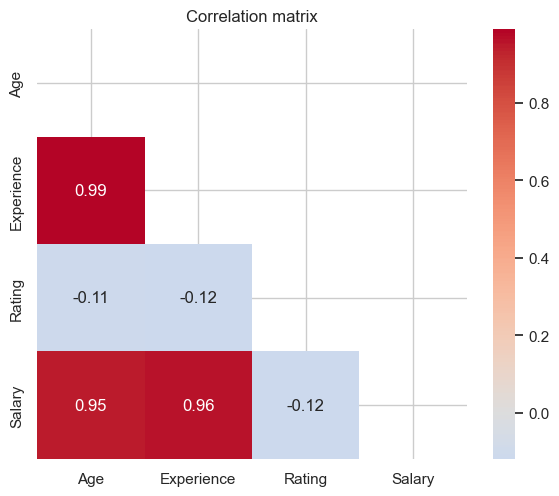


Variance Inflation Factor (VIF):
 Age           49.66
Experience    60.15
Rating         1.02
Salary        11.99
(VIF > 5 suggests the column is largely explained by the other columns)

PCA explained variance by component:
component  explained_%  cumulative_%
      PC1         73.8          73.8
      PC2         24.5          98.3
      PC3          1.5          99.8
      PC4          0.2         100.0


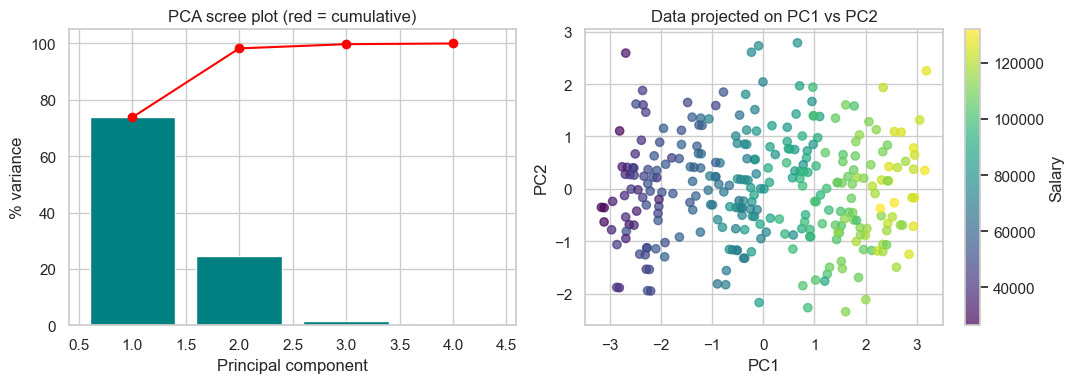

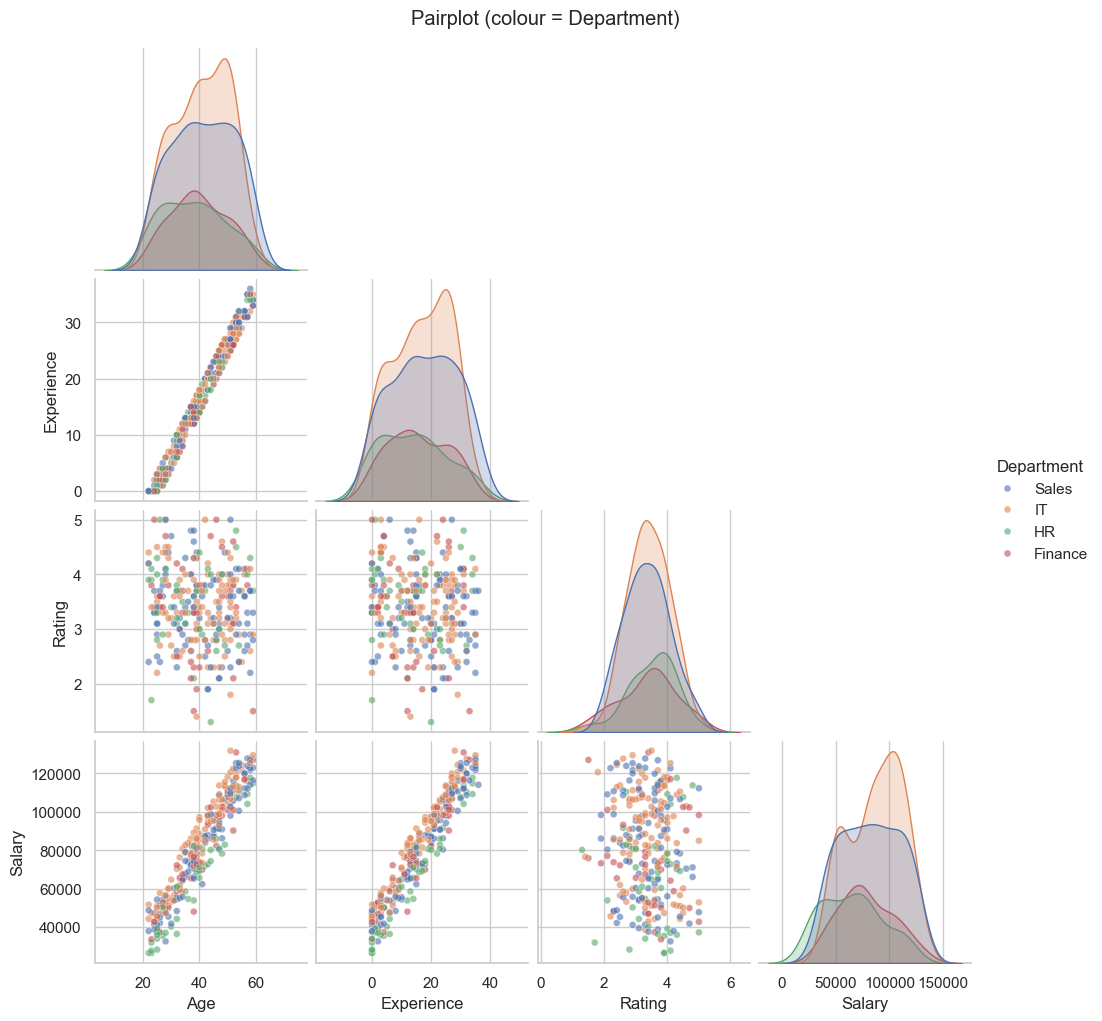

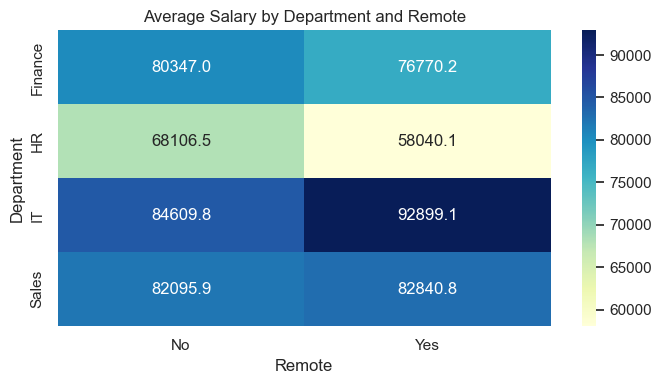


 KEY FINDINGS
1. 'Rating' has 12 missing values (4.0%).
2. Dataset: 300 rows, 6 columns (4 numeric, 2 categorical).
3. 'Rating' has 1 outlier(s) (IQR rule).
4. 'Age' and 'Experience' are highly correlated (r=0.99).
5. 'Experience' and 'Salary' are highly correlated (r=0.96).
6. 'Age' and 'Salary' are highly correlated (r=0.95).
7. 'Salary' differs significantly across 'Department' groups (p=0.000); highest in 'IT', lowest in 'HR'.
8. 'Department' and 'Remote' are associated (chi-square p=0.024, Cramer's V=0.18).
9. 'Age' has high multicollinearity (VIF=49.7).
10. 'Experience' has high multicollinearity (VIF=60.1).
11. 'Salary' has high multicollinearity (VIF=12.0).
12. 2 principal component(s) capture 90% of the variance of 4 numeric columns.

Report saved to eda_toolkit_output/eda_report.md


In [4]:
eda = EDAToolkit(df, target_col='Salary', save_dir='eda_toolkit_output')
eda.run_all()

## 3. Or run one level at a time


 1. UNIVARIATE ANALYSIS
Numeric summary:
             count      mean       std      min      25%      50%        75%  \
Age         300.0     40.45     10.34     22.0     32.0     40.0      49.00   
Experience  300.0     16.56     10.26      0.0      8.0     16.0      25.00   
Rating      288.0      3.40      0.74      1.3      2.9      3.4       3.90   
Salary      300.0  81201.66  26970.52  26571.0  58380.5  81455.0  105387.25   

                 max  skew  kurtosis  outliers  
Age             59.0 -0.04     -1.10         0  
Experience      36.0 -0.02     -1.13         0  
Rating           5.0 -0.16     -0.16         1  
Salary      131855.0 -0.09     -1.07         0  


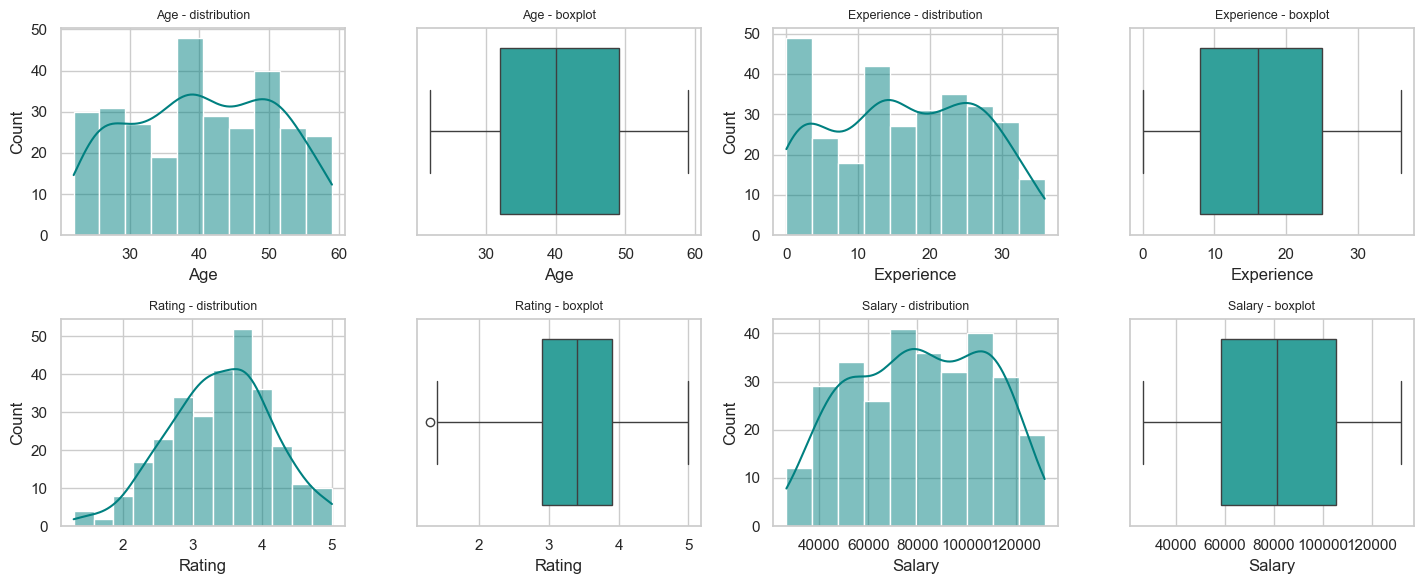


Department (% of rows):
Department
IT         38.3
Sales      33.0
HR         15.0
Finance    13.7

Remote (% of rows):
Remote
No     63.3
Yes    36.7


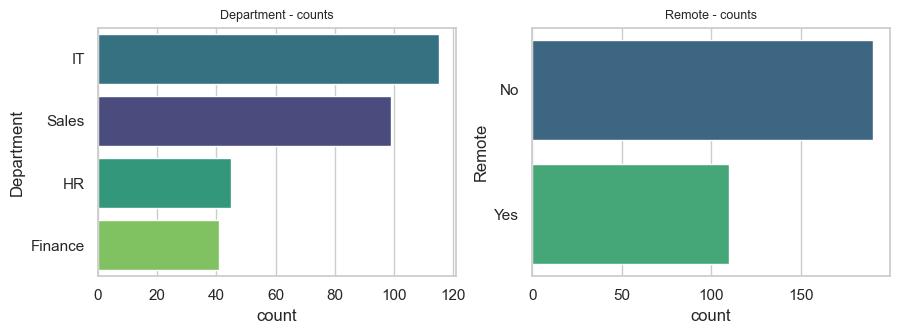

In [5]:
EDAToolkit(df, target_col='Salary').univariate()


 2. BIVARIATE ANALYSIS
--- Numeric vs Numeric ---
     col_1      col_2  pearson  spearman
       Age Experience    0.990     0.989
Experience     Salary    0.957     0.958
       Age     Salary    0.948     0.949
Experience     Rating   -0.119    -0.105
    Rating     Salary   -0.118    -0.116
       Age     Rating   -0.113    -0.100
(Pearson = straight-line relationship, Spearman = any rising/falling relationship)


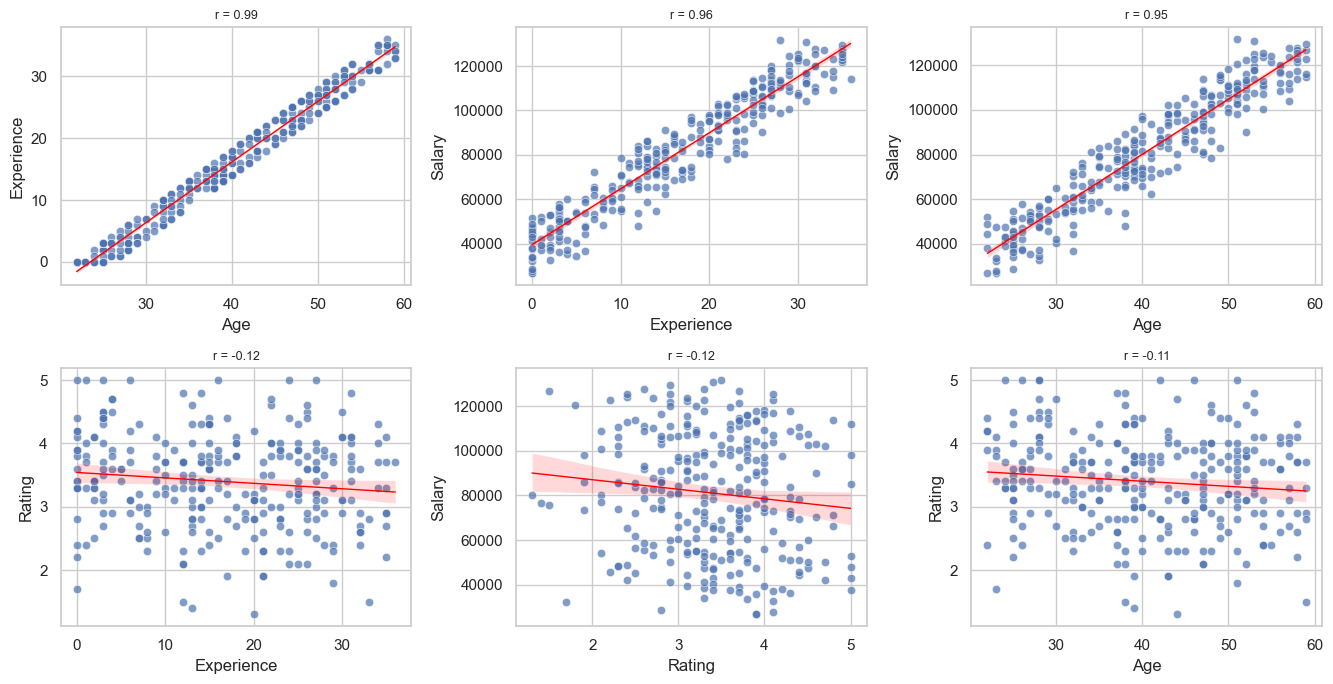


--- Category vs Numeric ---
  category numeric highest_group lowest_group  p_value
Department  Salary            IT           HR   0.0001
    Remote  Salary           Yes           No   0.5288
(p_value < 0.05 means the group averages are really different, not just chance)


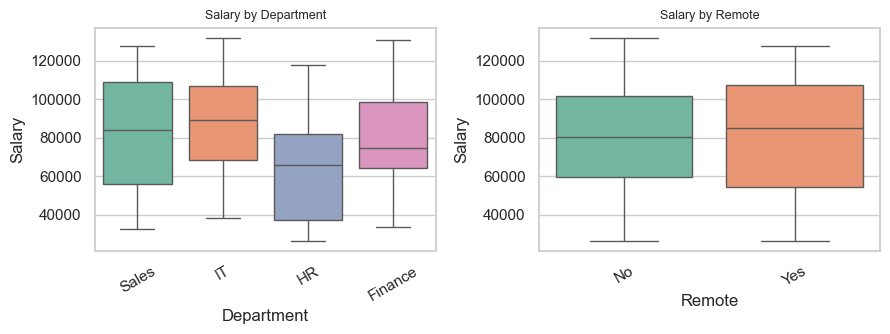


--- Category vs Category ---


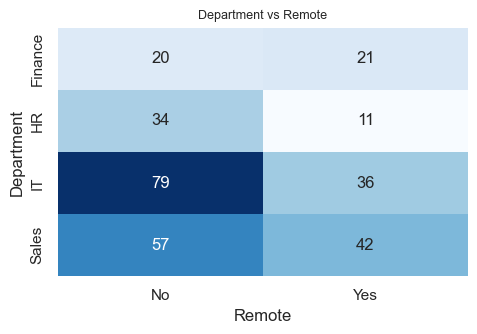

     col_1  col_2  p_value  cramers_v
Department Remote   0.0236     0.1777
(Cramer's V: 0 = no link, 1 = perfect link)


In [6]:
EDAToolkit(df, target_col='Salary').bivariate()


 3. MULTIVARIATE ANALYSIS


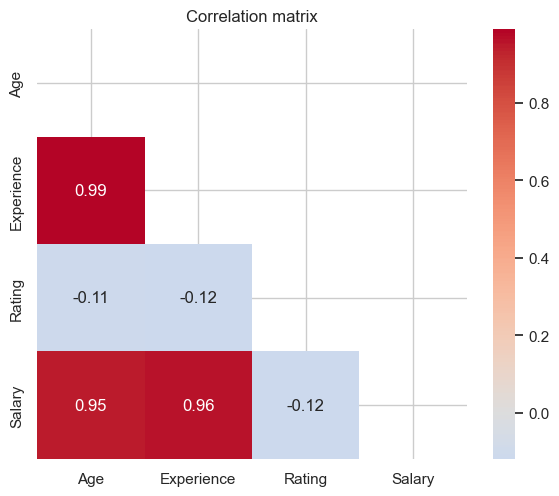


Variance Inflation Factor (VIF):
 Age           49.66
Experience    60.15
Rating         1.02
Salary        11.99
(VIF > 5 suggests the column is largely explained by the other columns)

PCA explained variance by component:
component  explained_%  cumulative_%
      PC1         73.8          73.8
      PC2         24.5          98.3
      PC3          1.5          99.8
      PC4          0.2         100.0


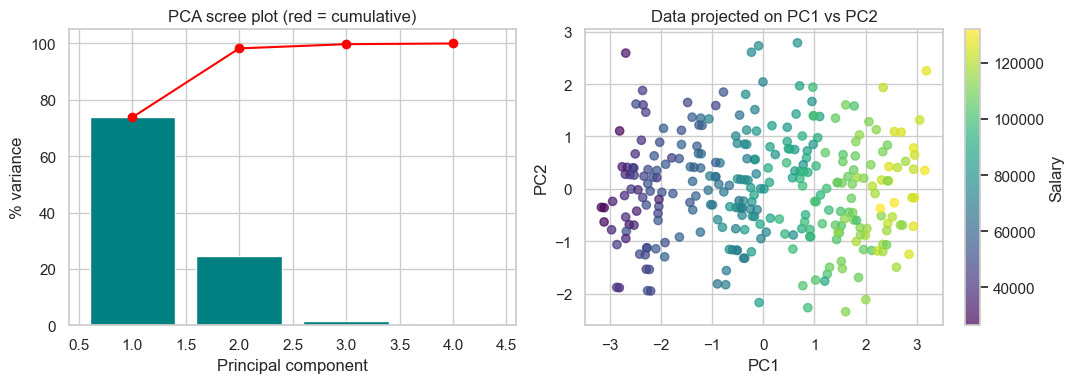

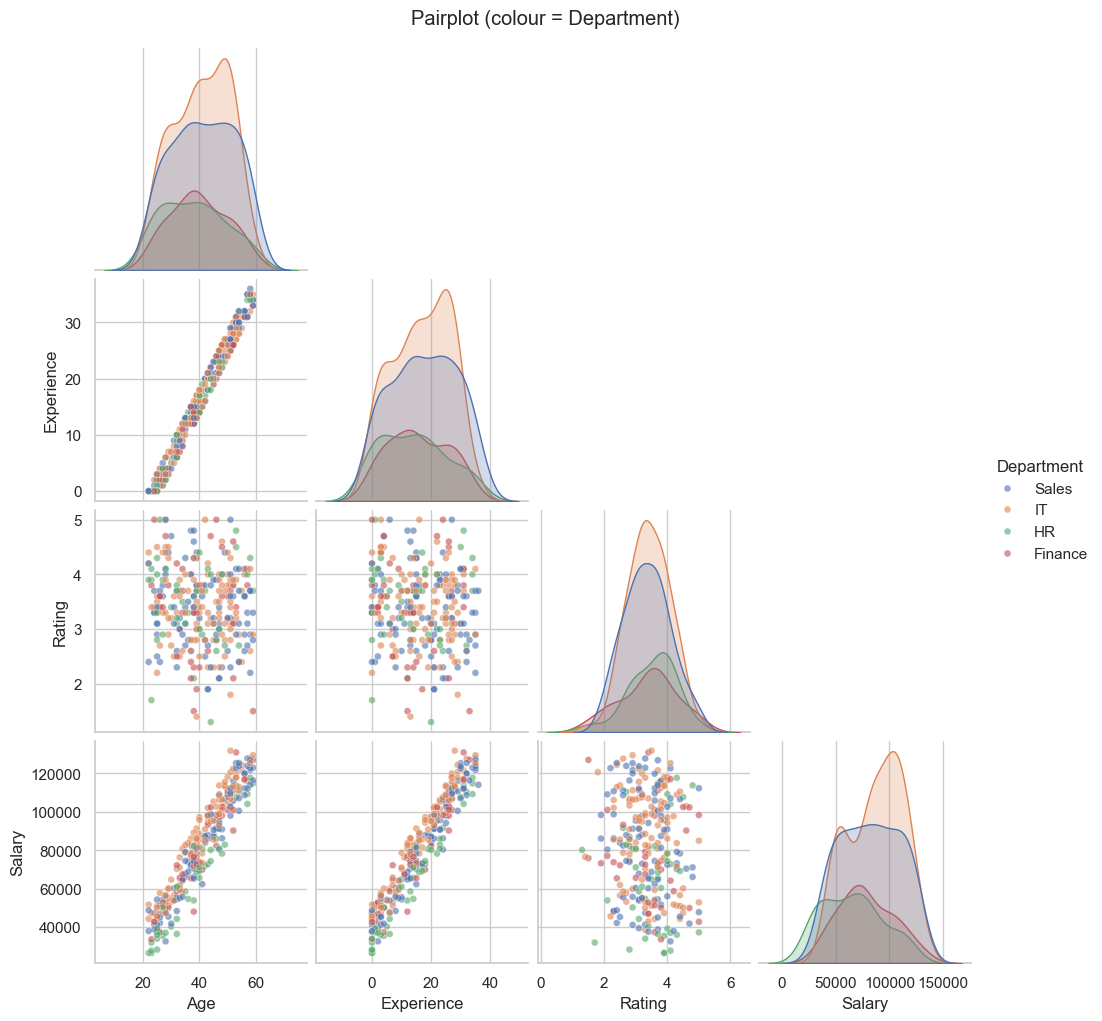

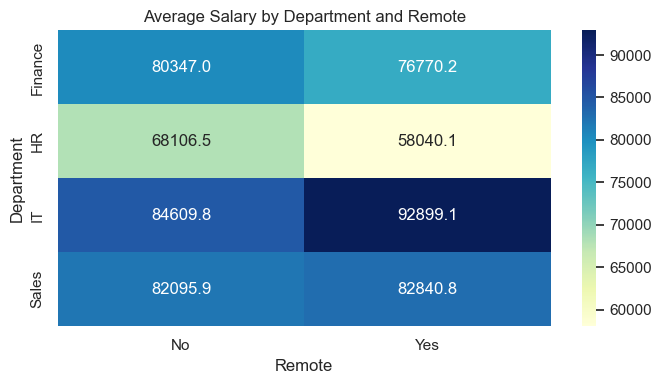

In [7]:
EDAToolkit(df, target_col='Salary').multivariate()